In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# Load the Breast Cancer dataset
dataset = load_breast_cancer()

# Separate input features and target
X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

y = dataset.target

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset Shape:", X.shape)

print("\nTarget Classes:")
print(dataset.target_names)

print("\nFirst 5 Records:")
display(X.head())

Dataset loaded successfully!
Dataset Shape: (569, 30)

Target Classes:
['malignant' 'benign']

First 5 Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Check dataset information
print("Number of Records:", X.shape[0])
print("Number of Features:", X.shape[1])

# Check for missing values
print("\nMissing Values:", X.isnull().sum().sum())

# Check target class distribution
print("\nClass Distribution:")
print(
    pd.Series(y)
    .map({0: "Malignant", 1: "Benign"})
    .value_counts()
)

# Statistical summary
print("\nStatistical Summary:")
display(X.describe())

Number of Records: 569
Number of Features: 30

Missing Values: 0

Class Distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

Statistical Summary:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [4]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining data split completed successfully!")

Training Records: 455
Testing Records: 114

Training data split completed successfully!


In [5]:
# Create a scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (455, 30)
Scaled testing data shape: (114, 30)


In [6]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=2000)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Make predictions on test data
logistic_predictions = logistic_model.predict(X_test_scaled)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

# Display accuracy
print("Logistic Regression Model Trained Successfully!")
print("Accuracy:", round(logistic_accuracy * 100, 2), "%")

Logistic Regression Model Trained Successfully!
Accuracy: 98.25 %


In [7]:
# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_model.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)

# Display accuracy
print("Decision Tree Model Trained Successfully!")
print("Accuracy:", round(tree_accuracy * 100, 2), "%")

Decision Tree Model Trained Successfully!
Accuracy: 92.11 %


In [8]:
# Compare model accuracy
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy (%)": [
        round(logistic_accuracy * 100, 2),
        round(tree_accuracy * 100, 2)
    ]
})

display(comparison)

# Identify the model with higher accuracy
best_model = comparison.loc[
    comparison["Accuracy (%)"].idxmax(),
    "Model"
]

print("Best Model Based on Accuracy:", best_model)

,Model,Accuracy (%)
0,Logistic Regression,98.25
1,Decision Tree,92.11


Best Model Based on Accuracy: Logistic Regression


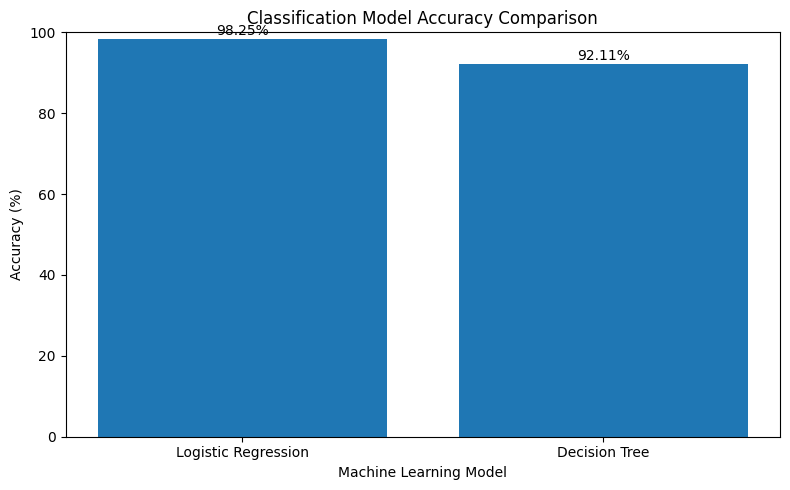

In [9]:
# Plot model accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

# Display accuracy values on the bars
for i, value in enumerate(comparison["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [10]:
# Logistic Regression evaluation
print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=dataset.target_names
))

# Decision Tree evaluation
print("DECISION TREE REPORT")
print(classification_report(
    y_test,
    tree_predictions,
    target_names=dataset.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

DECISION TREE REPORT
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



In [11]:
# Final observations
print("DAY 11: CLASSIFICATION ALGORITHMS")
print("=" * 40)

print("Dataset: Breast Cancer Wisconsin")
print("Total Records:", X.shape[0])
print("Total Features:", X.shape[1])

print("\nModel Accuracy:")
print("Logistic Regression:",
      round(logistic_accuracy * 100, 2), "%")
print("Decision Tree:",
      round(tree_accuracy * 100, 2), "%")

print("\nBest Model Based on Accuracy:", best_model)

print("\nKey Observations:")
print("1. Classification predicts predefined categories.")
print("2. Logistic Regression uses a linear decision boundary.")
print("3. Decision Tree learns feature-based decision rules.")
print("4. Both models were evaluated on the same test set.")
print("5. Accuracy alone is not sufficient for medical decisions.")

DAY 11: CLASSIFICATION ALGORITHMS
Dataset: Breast Cancer Wisconsin
Total Records: 569
Total Features: 30

Model Accuracy:
Logistic Regression: 98.25 %
Decision Tree: 92.11 %

Best Model Based on Accuracy: Logistic Regression

Key Observations:
1. Classification predicts predefined categories.
2. Logistic Regression uses a linear decision boundary.
3. Decision Tree learns feature-based decision rules.
4. Both models were evaluated on the same test set.
5. Accuracy alone is not sufficient for medical decisions.
